In [1]:
import os, sys, random, cv2, torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from torchvision.datasets import FashionMNIST

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.13
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB


In [2]:
# Cell 2 — Config, seed, device, folders

CONFIG = {
    "image_size": 256,
    "canny_low": 100,
    "canny_high": 200,
    "seed": 42,
    "selected_labels": [3, 7],   # dress, sneaker
    "max_training_steps": 3000,
    "batch_size": 2
}

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed(CONFIG["seed"])

device = "cuda" if torch.cuda.is_available() else "cpu"

os.makedirs("outputs", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

print("Device:", device)
print("Selected labels:", CONFIG["selected_labels"])
print("Folders ready.")

Device: cuda
Selected labels: [3, 7]
Folders ready.


In [3]:
def save_image(tensor, path):
    image = tensor.detach().cpu()
    image = ((image + 1) / 2).clamp(0, 1)
    image = (image.permute(1, 2, 0).numpy() * 255).astype("uint8")
    Image.fromarray(image).save(path)

print("save_image() ready")

save_image() ready


100%|██████████| 26.4M/26.4M [00:02<00:00, 11.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.5MB/s]


Filtered training samples: 12000
Filtered testing samples: 2000


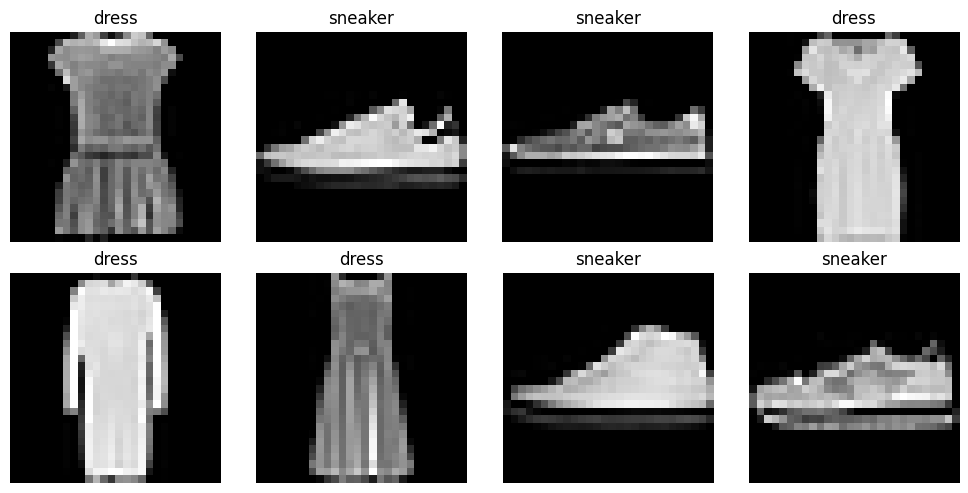

In [4]:
# Cell 4 — Load Fashion-MNIST and filter to selected labels

full_train_data = FashionMNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
full_test_data  = FashionMNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

selected_labels = CONFIG["selected_labels"]

train_indices = [i for i, (_, label) in enumerate(full_train_data) if label in selected_labels]
test_indices  = [i for i, (_, label) in enumerate(full_test_data) if label in selected_labels]

from torch.utils.data import Subset
train_data = Subset(full_train_data, train_indices)
test_data  = Subset(full_test_data, test_indices)

label_to_name = {
    3: "dress",
    7: "sneaker"
}

print("Filtered training samples:", len(train_data))
print("Filtered testing samples:", len(test_data))

# visualize filtered raw samples
plt.figure(figsize=(10, 5))
for i in range(8):
    img, label = train_data[i]
    plt.subplot(2, 4, i + 1)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(label_to_name[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

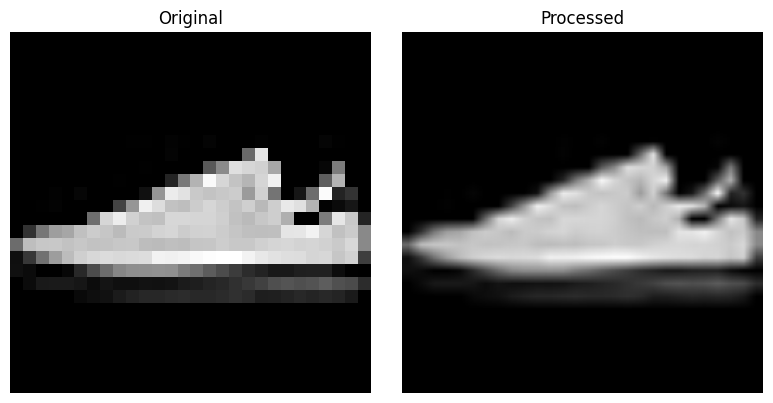

Processed shape: torch.Size([3, 256, 256])


In [5]:
preprocess = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

sample_img, _ = train_data[1]
sample_pil = transforms.ToPILImage()(sample_img)
processed_img = preprocess(sample_pil)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.squeeze(), cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(((processed_img.permute(1, 2, 0).numpy()) + 1) / 2)
plt.title("Processed")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Processed shape:", processed_img.shape)

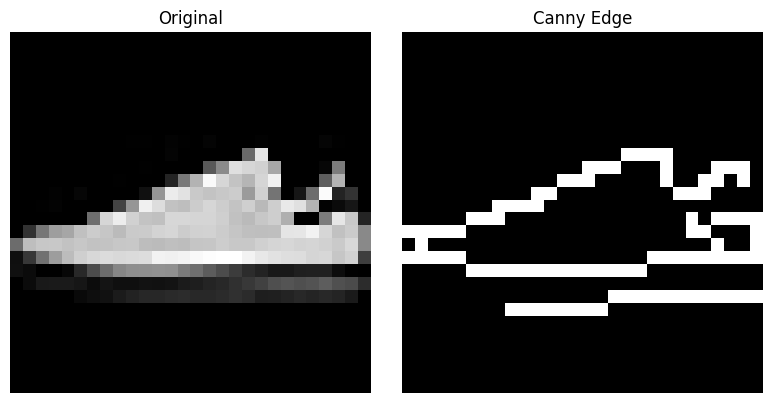

In [6]:
def generate_canny_edge(pil_img):
    gray = np.array(pil_img.convert("L"))
    edges = cv2.Canny(gray, CONFIG["canny_low"], CONFIG["canny_high"])
    return Image.fromarray(edges)

edge_img = generate_canny_edge(sample_pil)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_pil, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edge_img, cmap="gray")
plt.title("Canny Edge")
plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
# Cell 7 — Final dataset with image + edge map + prompt (2-label version)

from torch.utils.data import Dataset, DataLoader, random_split

def make_prompt(label):
    if label == 3:
        return "a dress, fashion product photo, studio lighting, high quality"
    elif label == 7:
        return "a sneaker, fashion product photo, studio lighting, high quality"

class FashionSketchDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        pil_img = transforms.ToPILImage()(img)

        target = preprocess(pil_img)
        edge = preprocess(generate_canny_edge(pil_img))
        prompt = make_prompt(label)

        return {
            "image": target,
            "edge": edge,
            "prompt": prompt,
            "label": label
        }

# split filtered train_data
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_split, val_split = random_split(train_data, [train_size, val_size])

train_dataset = FashionSketchDataset(train_split)
val_dataset   = FashionSketchDataset(val_split)
test_dataset  = FashionSketchDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 9600
Validation samples: 2400
Test samples: 2000


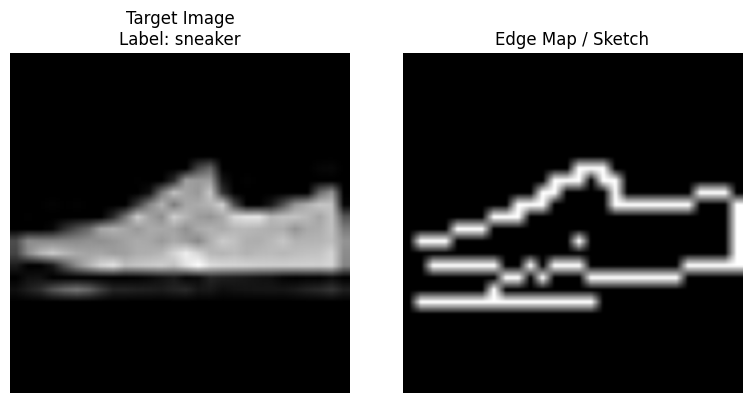

Prompt: a sneaker, fashion product photo, studio lighting, high quality


In [8]:
# Cell 8 — Visualize one filtered training sample

sample = train_dataset[0] # CHANGE THE NUMBER HERE TO TEST DIFFERENT SAMPLES

image = sample["image"]
edge = sample["edge"]
prompt = sample["prompt"]
label = sample["label"]

image_display = ((image.permute(1, 2, 0).numpy()) + 1) / 2
edge_display = ((edge.permute(1, 2, 0).numpy()) + 1) / 2

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_display)
plt.title(f"Target Image\nLabel: {label_to_name[label]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edge_display)
plt.title("Edge Map / Sketch")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prompt:", prompt)

In [9]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler
import torch

# Use float16 if running on GPU
dtype = torch.float32

# Load ControlNet (Canny)
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-canny",
    torch_dtype=dtype
)

# Load Stable Diffusion v1.5 with ControlNet
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=dtype,
    safety_checker=None
)

# Replace scheduler for faster and cleaner inference
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

# Move pipeline to GPU/CPU
pipe = pipe.to(device)

print("Stable Diffusion v1.5 + ControlNet loaded successfully.")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recomme

config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/1.45G [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results

Stable Diffusion v1.5 + ControlNet loaded successfully.


In [10]:
# Cell 10 — Freeze Stable Diffusion components and train only ControlNet

# Freeze UNet
for param in pipe.unet.parameters():
    param.requires_grad = False

# Freeze VAE
for param in pipe.vae.parameters():
    param.requires_grad = False

# Freeze text encoder
for param in pipe.text_encoder.parameters():
    param.requires_grad = False

# Keep ControlNet trainable
for param in pipe.controlnet.parameters():
    param.requires_grad = True

# Count trainable parameters
trainable_params = sum(p.numel() for p in pipe.controlnet.parameters() if p.requires_grad)
frozen_unet = sum(p.numel() for p in pipe.unet.parameters() if not p.requires_grad)

print("ControlNet trainable parameters:", trainable_params)
print("UNet frozen parameters:", frozen_unet)
print("Base model frozen. Only ControlNet will be trained.")

ControlNet trainable parameters: 361279120
UNet frozen parameters: 859520964
Base model frozen. Only ControlNet will be trained.


In [11]:
# Cell 11 — Create optimizer for ControlNet training

import torch.optim as optim

optimizer = optim.AdamW(
    pipe.controlnet.parameters(),
    lr=1e-6,
    betas=(0.9, 0.999),
    weight_decay=1e-2
)

print("Optimizer created successfully.")
print("Learning rate:", optimizer.param_groups[0]["lr"])

Optimizer created successfully.
Learning rate: 1e-06


In [12]:
# Cell 12 — Resume training from latest valid checkpoint

checkpoint_dir = "checkpoints"

resume_epoch = 0
resume_global_step = 0
resume_step_in_epoch = 0

if not os.path.exists(checkpoint_dir):
    os.makedirs(checkpoint_dir)

checkpoint_files = [
    f for f in os.listdir(checkpoint_dir)
    if f.startswith("controlnet_epoch_") and f.endswith(".pt")
]

checkpoint_files.sort(reverse=True)
loaded = False

for ckpt_file in checkpoint_files:
    checkpoint_path = os.path.join(checkpoint_dir, ckpt_file)

    try:
        checkpoint = torch.load(checkpoint_path, map_location=device)

        pipe.controlnet.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        resume_epoch = checkpoint["epoch"]
        resume_global_step = checkpoint["global_step"]
        resume_step_in_epoch = checkpoint["step_in_epoch"]

        print(f"Resumed from checkpoint: {ckpt_file}")
        print(f"Resume epoch: {resume_epoch}")
        print(f"Resume global step: {resume_global_step}")
        print(f"Resume step in epoch: {resume_step_in_epoch}")

        loaded = True
        break

    except Exception as e:
        print(f"Skipping corrupted checkpoint: {ckpt_file}")
        print("Error:", e)

if not loaded:
    print("No valid checkpoint found. Starting from epoch 0, step 0.")

No valid checkpoint found. Starting from epoch 0, step 0.


In [13]:
# Cell 13 — Prepare noise scheduler for diffusion training

from diffusers import DDPMScheduler

noise_scheduler = DDPMScheduler.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="scheduler"
)

print("Noise scheduler loaded successfully.")
print("Number of training timesteps:", noise_scheduler.config.num_train_timesteps)

Noise scheduler loaded successfully.
Number of training timesteps: 1000


In [17]:
# Cell 14 — Tokenizer Full training loop with epoch-aware resume and 1000-step checkpoints
tokenizer = pipe.tokenizer
text_encoder = pipe.text_encoder

print("Tokenizer and text encoder initialized successfully.")


num_epochs = 5
save_every_steps = 1000

global_step = resume_global_step
loss_history = []

pipe.controlnet.train()

for epoch in range(resume_epoch, num_epochs):
    print(f"\nStarting Epoch {epoch + 1}/{num_epochs}")

    step_in_epoch = 0

    for batch_idx, batch in enumerate(train_loader):

        # Skip already completed batches if resuming inside the same epoch
        if epoch == resume_epoch and batch_idx < resume_step_in_epoch:
            continue

        optimizer.zero_grad()

        images = batch["image"].to(device=device, dtype=dtype)

        with torch.no_grad():
            latents = pipe.vae.encode(images).latent_dist.sample()
            latents = latents * pipe.vae.config.scaling_factor

        noise = torch.randn_like(latents)

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],),
            device=device
        ).long()

        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        tokens = tokenizer(
            batch["prompt"],
            padding="max_length",
            truncation=True,
            max_length=tokenizer.model_max_length,
            return_tensors="pt"
        )

        input_ids = tokens.input_ids.to(device)

        with torch.no_grad():
            text_embeddings = text_encoder(input_ids)[0]

        edge_maps = batch["edge"].to(device=device, dtype=dtype)
        control_image = (edge_maps + 1) / 2

        down_block_res_samples, mid_block_res_sample = pipe.controlnet(
            noisy_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            controlnet_cond=control_image,
            return_dict=False
        )

        noise_pred = pipe.unet(
            noisy_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            down_block_additional_residuals=down_block_res_samples,
            mid_block_additional_residual=mid_block_res_sample,
            return_dict=False
        )[0]

        if not torch.isfinite(noise_pred).all():
            print("NaN or Inf detected in noise prediction. Stopping training.")
            break

        loss = torch.nn.functional.mse_loss(noise_pred.float(), noise.float())

        if not torch.isfinite(loss):
            print("NaN or Inf detected in loss. Stopping training.")
            break

        loss.backward()
        torch.nn.utils.clip_grad_norm_(pipe.controlnet.parameters(), 1.0)
        optimizer.step()

        global_step += 1
        step_in_epoch = batch_idx + 1
        loss_history.append(loss.item())

        if global_step % 200 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs} | "
                f"Batch {step_in_epoch}/{len(train_loader)} | "
                f"Global Step {global_step} | "
                f"Loss: {loss.item():.4f}"
            )

        # Save checkpoint every 1000 steps within each epoch
        if step_in_epoch % save_every_steps == 0:
            checkpoint_path = (
                f"checkpoints/controlnet_epoch_{epoch+1}_step_{step_in_epoch}.pt"
            )

            torch.save({
                "epoch": epoch,
                "global_step": global_step,
                "step_in_epoch": step_in_epoch,
                "model_state_dict": pipe.controlnet.state_dict(),
                "optimizer_state_dict": optimizer.state_dict()
            }, checkpoint_path)

            print(f"Checkpoint saved at: {checkpoint_path}")

    # Save checkpoint at end of every epoch
    epoch_checkpoint_path = f"checkpoints/controlnet_epoch_{epoch+1}_final.pt"
    torch.save({
        "epoch": epoch + 1,
        "global_step": global_step,
        "step_in_epoch": 0,
        "model_state_dict": pipe.controlnet.state_dict(),
        "optimizer_state_dict": optimizer.state_dict()
    }, epoch_checkpoint_path)

    print(f"End-of-epoch checkpoint saved at: {epoch_checkpoint_path}")

print("Training completed.")

Tokenizer and text encoder initialized successfully.

Starting Epoch 1/5
Epoch 1/5 | Batch 200/4800 | Global Step 200 | Loss: 0.1419
Epoch 1/5 | Batch 400/4800 | Global Step 400 | Loss: 0.0849
Epoch 1/5 | Batch 600/4800 | Global Step 600 | Loss: 0.0446
Epoch 1/5 | Batch 800/4800 | Global Step 800 | Loss: 0.0277
Epoch 1/5 | Batch 1000/4800 | Global Step 1000 | Loss: 0.0178
Checkpoint saved at: checkpoints/controlnet_epoch_1_step_1000.pt
Epoch 1/5 | Batch 1200/4800 | Global Step 1200 | Loss: 0.0360
Epoch 1/5 | Batch 1400/4800 | Global Step 1400 | Loss: 0.0061
Epoch 1/5 | Batch 1600/4800 | Global Step 1600 | Loss: 0.0458
Epoch 1/5 | Batch 1800/4800 | Global Step 1800 | Loss: 0.0547
Epoch 1/5 | Batch 2000/4800 | Global Step 2000 | Loss: 0.0420
Checkpoint saved at: checkpoints/controlnet_epoch_1_step_2000.pt
Epoch 1/5 | Batch 2200/4800 | Global Step 2200 | Loss: 0.0137
Epoch 1/5 | Batch 2400/4800 | Global Step 2400 | Loss: 0.0250
Epoch 1/5 | Batch 2600/4800 | Global Step 2600 | Loss: 0.2327

  0%|          | 0/30 [00:00<?, ?it/s]

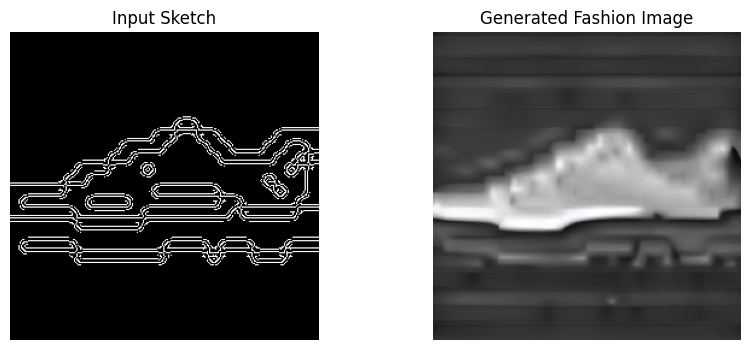

Generated image saved to outputs/generated_sample.png


In [18]:
# Cell 15 — Generate fashion image from filtered test sketch

def generate_from_sketch(sketch_pil, prompt, steps=30, guidance=7.5):
    edge_img = generate_canny_edge(sketch_pil)
    edge_img = edge_img.resize((CONFIG["image_size"], CONFIG["image_size"]))

    result = pipe(
        prompt=prompt,
        image=edge_img,
        num_inference_steps=steps,
        guidance_scale=guidance
    ).images[0]

    return edge_img, result

test_sample = test_dataset[0] # CHANGE THE NUMBER HERE TO TEST DIFFERENT SAMPLES

sketch_input = transforms.ToPILImage()(test_sample["edge"])
prompt = test_sample["prompt"]

edge, generated = generate_from_sketch(sketch_input, prompt)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(edge, cmap="gray")
plt.title("Input Sketch")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(generated)
plt.title("Generated Fashion Image")
plt.axis("off")

plt.show()

generated.save("outputs/generated_sample.png")
print("Generated image saved to outputs/generated_sample.png")

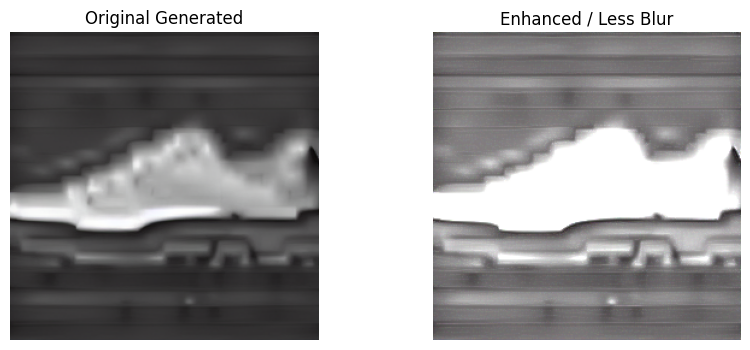

In [19]:
# Cell 16 — Strong blur reduction using Laplacian sharpening

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load generated image
img = cv2.imread("outputs/generated_sample.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# -------- Step 1: Unsharp masking --------
blur = cv2.GaussianBlur(img, (0,0), sigmaX=1.2, sigmaY=1.2)
sharp = cv2.addWeighted(img, 1.8, blur, -0.8, 0)

# -------- Step 2: Laplacian edge enhancement --------
laplacian = cv2.Laplacian(sharp, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

enhanced = cv2.addWeighted(sharp, 1.5, laplacian, 0.5, 0)

# -------- Step 3: Improve contrast --------
alpha = 1.3
beta = 10
enhanced = cv2.convertScaleAbs(enhanced, alpha=alpha, beta=beta)

# Save result
cv2.imwrite("outputs/generated_sample_sharp.png", cv2.cvtColor(enhanced, cv2.COLOR_RGB2BGR))

# Show comparison
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original Generated")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(enhanced)
plt.title("Enhanced / Less Blur")
plt.axis("off")

plt.show()

SSIM Score: -0.0024


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

... (4 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP Score: 0.1854


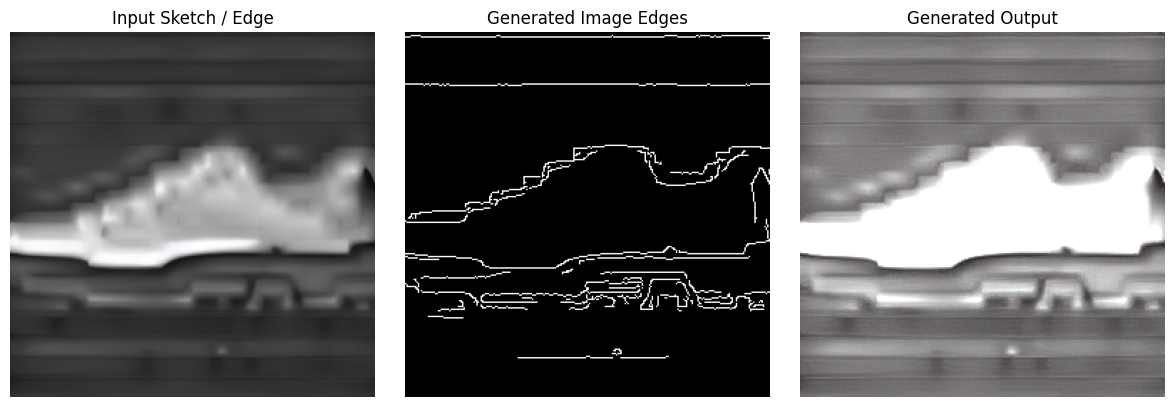

In [20]:
# Cell 17 — Evaluate generated image using proper SSIM and CLIP Score

from skimage.metrics import structural_similarity as ssim
from transformers import CLIPProcessor, CLIPModel

input_edge = Image.open("outputs/generated_sample.png").convert("RGB")
generated_img = Image.open("outputs/generated_sample_sharp.png").convert("RGB")

eval_size = 256
input_edge_resized = input_edge.resize((eval_size, eval_size))
generated_resized = generated_img.resize((eval_size, eval_size))

generated_gray = cv2.cvtColor(np.array(generated_resized), cv2.COLOR_RGB2GRAY)
generated_edges = cv2.Canny(generated_gray, CONFIG["canny_low"], CONFIG["canny_high"])

input_gray = cv2.cvtColor(np.array(input_edge_resized), cv2.COLOR_RGB2GRAY)

ssim_score = ssim(input_gray, generated_edges)
print("SSIM Score:", round(ssim_score, 4))

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

sample_prompt = test_dataset[0]["prompt"]

inputs = clip_processor(
    text=[sample_prompt],
    images=generated_resized,
    return_tensors="pt",
    padding=True
).to(device)

with torch.no_grad():
    outputs = clip_model(**inputs)
    image_embeds = outputs.image_embeds
    text_embeds = outputs.text_embeds
    clip_score = torch.nn.functional.cosine_similarity(image_embeds, text_embeds).item()

print("CLIP Score:", round(clip_score, 4))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_edge_resized)
plt.title("Input Sketch / Edge")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(generated_edges, cmap="gray")
plt.title("Generated Image Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(generated_resized)
plt.title("Generated Output")
plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
# Cell 18 — Human-in-the-loop evaluation template

import pandas as pd

user_eval = pd.DataFrame({
    "sample_id": [1, 2, 3, 4, 5, 6],
    "category": ["dress", "dress", "sneaker", "dress", "sneaker", "sneaker"],
    "sketch_following_score_1to5": ["", "", "", "", "", ""],
    "visual_quality_score_1to5": ["", "", "", "", "", ""],
    "prompt_alignment_score_1to5": ["", "", "", "", "", ""],
    "comments": ["", "", "", "", "", ""]
})

user_eval

,sample_id,category,sketch_following_score_1to5,visual_quality_score_1to5,prompt_alignment_score_1to5,comments
0,1,dress,,,,
1,2,dress,,,,
2,3,sneaker,,,,
3,4,dress,,,,
4,5,sneaker,,,,
5,6,sneaker,,,,


In [22]:
# Cell 19 — Create messy sketch version for robustness testing

def make_messy_sketch(edge_pil):
    edge = np.array(edge_pil.convert("L"))

    noise = np.random.randint(0, 50, edge.shape, dtype=np.uint8)
    noisy = cv2.add(edge, noise)

    blurred = cv2.GaussianBlur(noisy, (3, 3), 0)

    kernel = np.ones((2, 2), np.uint8)
    thick = cv2.dilate(blurred, kernel, iterations=1)

    return Image.fromarray(thick)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

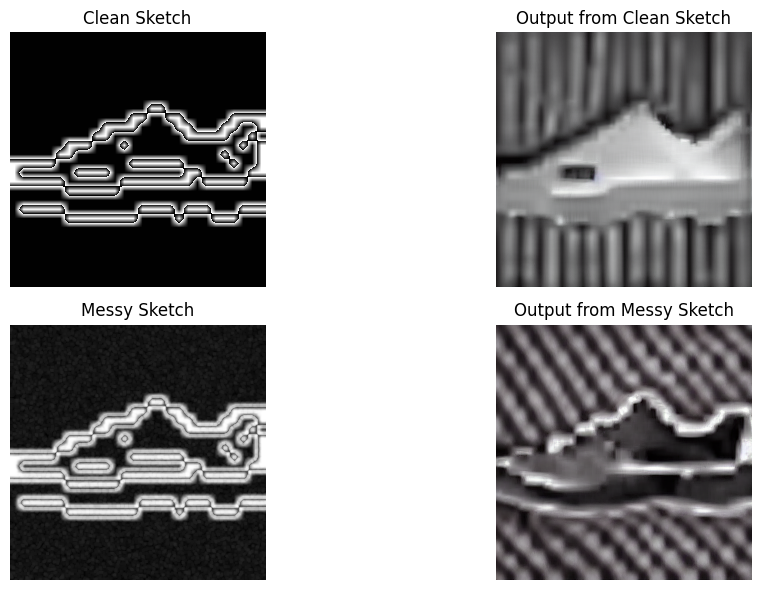

In [23]:
# Cell 20 — Compare clean vs messy sketch robustness

sample = test_dataset[0] # CHANGE THE NUMBER HERE TO TEST DIFFERENT SAMPLES

clean_sketch = transforms.ToPILImage()(sample["edge"])
messy_sketch = make_messy_sketch(clean_sketch)
prompt = sample["prompt"]

clean_result = pipe(
    prompt=prompt,
    image=clean_sketch,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

messy_result = pipe(
    prompt=prompt,
    image=messy_sketch,
    num_inference_steps=30,
    guidance_scale=7.5
).images[0]

plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(clean_sketch, cmap="gray")
plt.title("Clean Sketch")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(clean_result)
plt.title("Output from Clean Sketch")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(messy_sketch, cmap="gray")
plt.title("Messy Sketch")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(messy_result)
plt.title("Output from Messy Sketch")
plt.axis("off")

plt.tight_layout()
plt.show()